# 03 – Logistic Regression baseline

Logistic regression trained on the prepared data (no SMOTE).
Benchmark: the logistic regression from the SMOTE experiment (AUC 0.807, Brier 0.052), built with the thesis preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from scipy.stats import ks_2samp

In [2]:
train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

target = "SeriousDlqin2yrs"
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

print(X_train.shape, X_test.shape)
print(list(X_train.columns))

(119999, 14) (30000, 14)
['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'income_missing', 'dependents_missing', 'special_code', 'util_invalid']


## 1. Train the model

In [3]:
# Escalar: aprender media y desvío SOLO del train
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.fit_transform(X_test)

# Entrenar la Logistica (sin smote)
logit = LogisticRegression(max_iter=1000, random_state=42)
logit.fit(X_train_sc, y_train)

# PD estimada para cada cliente del test
pd_test = logit.predict_proba(X_test_sc)[:,1]

print('Modelo Entrenado')

Modelo Entrenado


In [4]:
def evaluar(nombre, y_real, pd_estimada):
    """Discrimination and calibration metrics for a PD model."""
    auc = roc_auc_score(y_real, pd_estimada)
    ks = ks_2samp(pd_estimada[y_real == 1], pd_estimada[y_real == 0]).statistic
    return {
        "Model": nombre,
        "AUC": round(auc, 4),
        "Gini": round(2 * auc - 1, 4),
        "KS": round(ks, 4),
        "Brier": round(brier_score_loss(y_real, pd_estimada), 4),
        "Avg PD": round(pd_estimada.mean(), 4),
    }

In [6]:
resultados = [
    {"Model": "Logit – thesis prep (experiment)", "AUC": 0.8072, "Gini": 0.6144,
     "KS": None, "Brier": 0.0522, "Avg PD": 0.0650},
    evaluar("Logit – new prep", y_test, pd_test),
]

pd.DataFrame(resultados)

,Model,AUC,Gini,KS,Brier,Avg PD
0,Logit – thesis prep (experiment),0.8072,0.6144,NaN,0.0522,0.0650
1,Logit – new prep,0.8592,0.7185,0.5611,0.0507,0.0668


In [7]:
sin_codigos = X_test["special_code"] == 0

resultados.append(
    evaluar("Logit – new prep (test without codes 96/98)",
            y_test[sin_codigos], pd_test[sin_codigos])
)

pd.DataFrame(resultados)

,Model,AUC,Gini,KS,Brier,Avg PD
0,Logit – thesis prep (experiment),0.8072,0.6144,NaN,0.0522,0.0650
1,Logit – new prep,0.8592,0.7185,0.5611,0.0507,0.0668
2,Logit – new prep (test without codes 96/98),0.8578,0.7157,0.5585,0.0504,0.0659


## 2. Coefficients and odds ratios

In [8]:
coefs = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": logit.coef_[0].round(4),
    "Odds ratio": np.exp(logit.coef_[0]).round(4),
}).sort_values("Coefficient", ascending=False)

coefs

,Variable,Coefficient,Odds ratio
0,RevolvingUtilizationOfUnsecuredLines,0.6369,1.8906
6,NumberOfTimes90DaysLate,0.3268,1.3866
2,NumberOfTime30-59DaysPastDueNotWorse,0.3040,1.3552
8,NumberOfTime60-89DaysPastDueNotWorse,0.2091,1.2326
5,NumberOfOpenCreditLinesAndLoans,0.1244,1.1325
7,NumberRealEstateLoansOrLines,0.1197,1.1272
12,special_code,0.0997,1.1049
9,NumberOfDependents,0.0602,1.0621
13,util_invalid,0.0391,1.0399
11,dependents_missing,-0.0110,0.9890


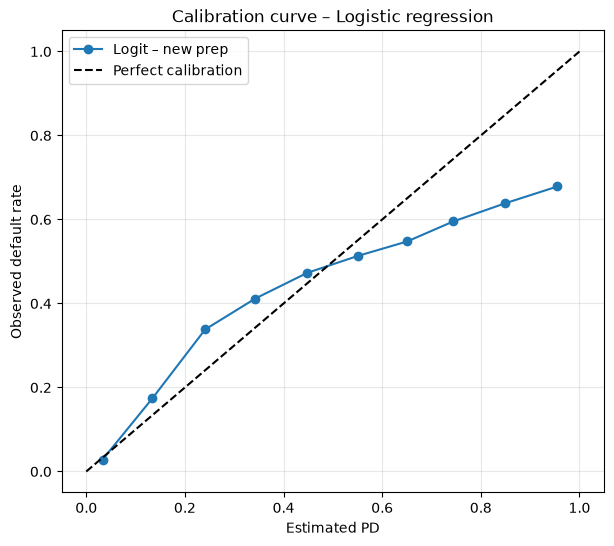

In [9]:
frac_real, prob_media = calibration_curve(y_test, pd_test, n_bins=10)

plt.figure(figsize=(7, 6))
plt.plot(prob_media, frac_real, marker="o", label="Logit – new prep")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Estimated PD")
plt.ylabel("Observed default rate")
plt.title("Calibration curve – Logistic regression")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/calibration_logit.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

**The new data preparation improves the model substantially.**

| Model | AUC | Gini | KS | Brier | Avg PD |
|---|---|---|---|---|---|
| Logit – thesis preprocessing (SMOTE experiment) | 0.807 | 0.614 | – | 0.0522 | 6.50% |
| Logit – new preprocessing | **0.859** | **0.719** | 0.561 | **0.0507** | 6.68% |
| Logit – new preprocessing, test without codes 96/98 | 0.858 | 0.716 | 0.559 | 0.0504 | 6.59% |

*Observed default rate in the test set: 6.68%.*

- **Discrimination:** AUC rises from 0.807 to 0.859, above the best model of the original thesis (XGBoost, 0.832). A simple, interpretable model with well-treated data outperforms a complex model with poorly treated data.
- **The gain is real:** excluding the 269 borrowers with codes 96/98 (removed in the thesis), AUC stays at 0.858. The improvement comes mainly from the rest of the preparation, not from keeping those borrowers.
- **Coefficients now make economic sense:** revolving utilization goes from −0.007 in the thesis to **+0.637**, becoming the strongest driver (odds ratio 1.89 per standard deviation). Past-due counts increase risk; age and income reduce it. `special_code` looks small in standardized terms, but it is a rare binary flag: having the code multiplies the odds of default by about 8, consistent with the EDA.
- **Calibration:** the average PD matches the observed default rate, and the curve is close to the diagonal for low PDs, where most borrowers are. The model underestimates risk between 10% and 45% and overestimates it above 50%, a pattern typical of non-linear relationships that a linear model cannot capture.

**Open points:**
- `DebtRatio` keeps a negative coefficient, against economic intuition. Possible causes: residual extreme values from near-zero incomes and correlation with real estate loans (0.40).
- The U-shape of open credit lines is approximated as a linear increase.

**Next steps:** XGBoost to capture non-linear effects (notebook 04) and post-hoc recalibration (notebook 05).